In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Global plot styling (matches your PDF template)
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 100

#section A
# Q1: Load dataset & display first/last 10 records
df = pd.read_csv('../data/Clean_Dataset.csv')
if 'Unnamed: 0' in df.columns:
    df.drop(columns=['Unnamed: 0'], inplace=True)

print("First 10 records:")
display(df.head(10))
print("Last 10 records:")
display(df.tail(10))

# Q2 & Q3: Shape, info, column types
print(f"\nQ2 - Shape: {df.shape[0]} rows, {df.shape[1]} columns (1 row = 1 flight booking option)")
print("\nQ3 - DataFrame Info:")
df.info()

# Q4: Memory usage before and after downcasting
mem_before = df.memory_usage(deep=True).sum() / (1024**2)
df_opt = df.copy()
for col in ['airline', 'source_city', 'departure_time', 'stops', 'arrival_time', 'destination_city', 'class']:
    df_opt[col] = df_opt[col].astype('category')
df_opt['days_left'] = pd.to_numeric(df_opt['days_left'], downcast='integer')
df_opt['price'] = pd.to_numeric(df_opt['price'], downcast='integer')
df_opt['duration'] = pd.to_numeric(df_opt['duration'], downcast='float')
mem_after = df_opt.memory_usage(deep=True).sum() / (1024**2)
print(f"\nQ4 - Memory before: {mem_before:.2f} MB | Memory after optimization: {mem_after:.2f} MB")

# Q5: Unique values & cardinality
print("\nQ5 - Unique values per column:")
print(df.nunique())

# Q6: Missing values
missing = pd.DataFrame({'Count': df.isnull().sum(), 'Percent': (df.isnull().sum()/len(df))*100})
print("\nQ6 - Missing values:\n", missing)

# Q7: Duplicate rows
dups = df.duplicated().sum()
print(f"\nQ7 - Exact duplicate rows: {dups}")


# Q8: Check categorical consistency
print("\nQ8 - Unique categorical values:")
for col in ['airline', 'source_city', 'destination_city', 'departure_time', 'arrival_time', 'stops', 'class']:
    print(f"{col}: {df[col].unique()}")
print("Sample flight codes (note IndiGo '0E+00' scientific notation artifact):", df[df['airline']=='Indigo']['flight'].unique()[:5])

# Q9: Price sanity check
print("\nQ9 - Price anomalies:")
print(f"Zero/Negative prices: {(df['price'] <= 0).sum()} | Min: {df['price'].min()} | Max: {df['price'].max()}")

First 10 records:


,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
0,SpiceJet,SG-8709,Delhi,Evening,zero,Night,Mumbai,Economy,2.17,1,5953
1,SpiceJet,SG-8157,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.33,1,5953
2,AirAsia,I5-764,Delhi,Early_Morning,zero,Early_Morning,Mumbai,Economy,2.17,1,5956
3,Vistara,UK-995,Delhi,Morning,zero,Afternoon,Mumbai,Economy,2.25,1,5955
4,Vistara,UK-963,Delhi,Morning,zero,Morning,Mumbai,Economy,2.33,1,5955
5,Vistara,UK-945,Delhi,Morning,zero,Afternoon,Mumbai,Economy,2.33,1,5955
6,Vistara,UK-927,Delhi,Morning,zero,Morning,Mumbai,Economy,2.08,1,6060
7,Vistara,UK-951,Delhi,Afternoon,zero,Evening,Mumbai,Economy,2.17,1,6060
8,GO_FIRST,G8-334,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.17,1,5954
9,GO_FIRST,G8-336,Delhi,Afternoon,zero,Evening,Mumbai,Economy,2.25,1,5954


Last 10 records:


,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
300143,Air_India,AI-440,Chennai,Early_Morning,one,Night,Hyderabad,Business,17.42,49,51345
300144,Air_India,AI-539,Chennai,Evening,one,Morning,Hyderabad,Business,18.92,49,51345
300145,Air_India,AI-430,Chennai,Morning,one,Morning,Hyderabad,Business,23.08,49,51345
300146,Air_India,AI-440,Chennai,Early_Morning,one,Morning,Hyderabad,Business,26.83,49,51345
300147,Air_India,AI-569,Chennai,Early_Morning,one,Night,Hyderabad,Business,17.25,49,68739
300148,Vistara,UK-822,Chennai,Morning,one,Evening,Hyderabad,Business,10.08,49,69265
300149,Vistara,UK-826,Chennai,Afternoon,one,Night,Hyderabad,Business,10.42,49,77105
300150,Vistara,UK-832,Chennai,Early_Morning,one,Night,Hyderabad,Business,13.83,49,79099
300151,Vistara,UK-828,Chennai,Early_Morning,one,Evening,Hyderabad,Business,10.00,49,81585
300152,Vistara,UK-822,Chennai,Morning,one,Evening,Hyderabad,Business,10.08,49,81585



Q2 - Shape: 300153 rows, 11 columns (1 row = 1 flight booking option)

Q3 - DataFrame Info:
<class 'pandas.DataFrame'>
RangeIndex: 300153 entries, 0 to 300152
Data columns (total 11 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   airline           300153 non-null  str    
 1   flight            300153 non-null  str    
 2   source_city       300153 non-null  str    
 3   departure_time    300153 non-null  str    
 4   stops             300153 non-null  str    
 5   arrival_time      300153 non-null  str    
 6   destination_city  300153 non-null  str    
 7   class             300153 non-null  str    
 8   duration          300153 non-null  float64
 9   days_left         300153 non-null  int64  
 10  price             300153 non-null  int64  
dtypes: float64(1), int64(2), str(8)
memory usage: 25.2 MB

Q4 - Memory before: 134.52 MB | Memory after optimization: 20.37 MB

Q5 - Unique values per column:
airline                

Q11 - Price Summary Statistics:
 Mean        2.088966e+04
Median      7.425000e+03
Mode        5.460800e+04
Std Dev     2.269777e+04
Variance    5.151886e+08
Min         1.105000e+03
Max         1.230710e+05
dtype: float64


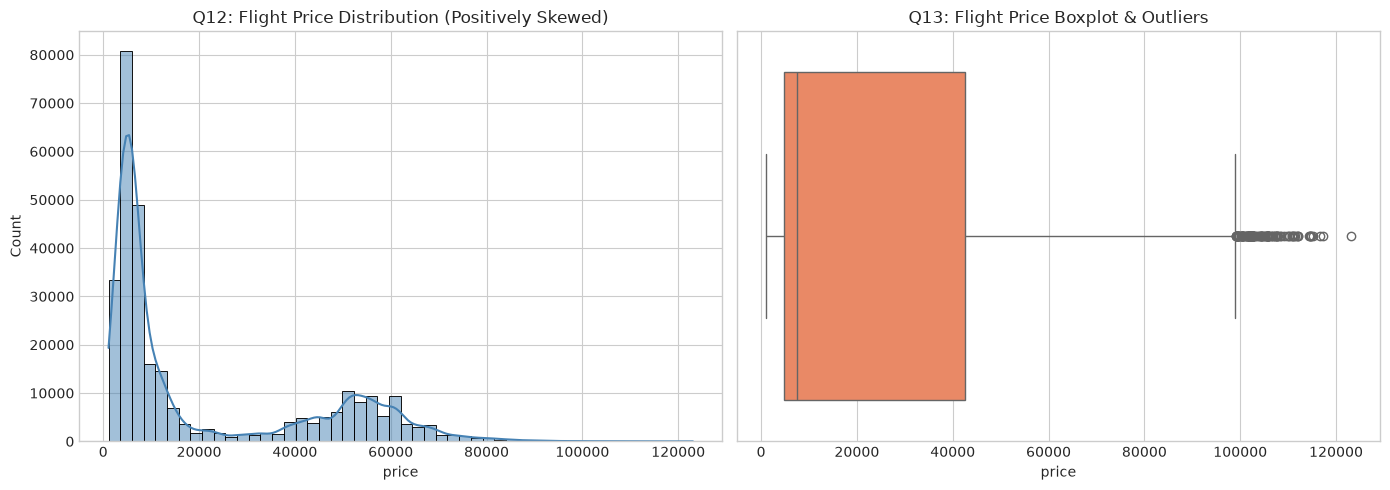

Q13 - IQR: 37738.00 | Upper Bound: 99128.00 | Outliers Count: 123

Q14 - Percentiles:
 0.05     2436.0
0.25     4783.0
0.50     7425.0
0.75    42521.0
0.90    57920.0
0.95    63277.0
0.99    76736.0
Name: price, dtype: float64

Q15 - Percentage of tickets below thresholds:
Below ₹3,000: 7.26%
Below ₹5,000: 27.11%
Below ₹10,000: 57.85%
Below ₹20,000: 68.38%
Below ₹50,000: 80.22%


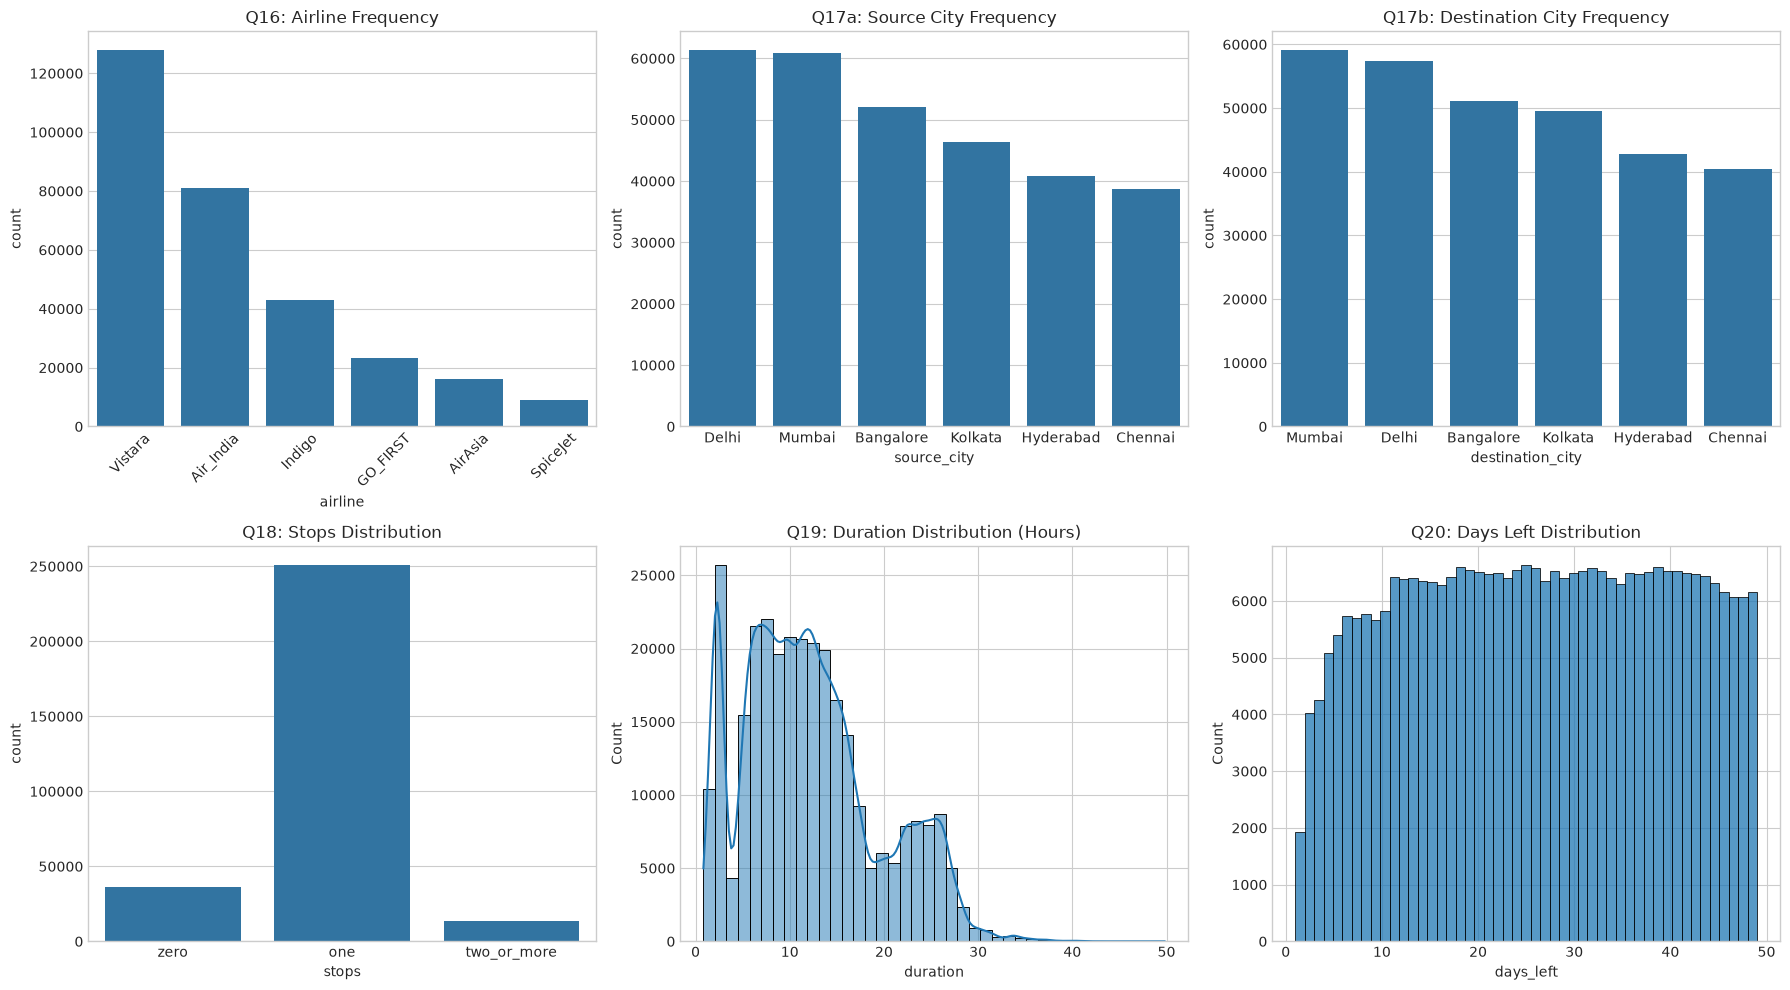


Q18 - Stops %:
 stops
one            83.578375
zero           11.995216
two_or_more     4.426409
Name: proportion, dtype: float64

Q19 - Duration | Min: 0.83h, Max: 49.83h, Median: 11.25h, Mean: 12.22h


In [4]:
#section B
# Q11: Summary stats for Price
price_stats = {
    'Mean': df['price'].mean(),
    'Median': df['price'].median(),
    'Mode': df['price'].mode()[0],
    'Std Dev': df['price'].std(),
    'Variance': df['price'].var(),
    'Min': df['price'].min(),
    'Max': df['price'].max()
}
print("Q11 - Price Summary Statistics:\n", pd.Series(price_stats))

# Q12 & Q13: Histogram/KDE & Boxplot with IQR outliers
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df['price'], bins=50, kde=True, ax=axes[0], color='steelblue')
axes[0].set_title('Q12: Flight Price Distribution (Positively Skewed)')
sns.boxplot(x=df['price'], ax=axes[1], color='coral')
axes[1].set_title('Q13: Flight Price Boxplot & Outliers')
plt.tight_layout()
plt.show()

Q1, Q3 = df['price'].quantile([0.25, 0.75])
IQR = Q3 - Q1
outliers = df[(df['price'] < Q1 - 1.5*IQR) | (df['price'] > Q3 + 1.5*IQR)]
print(f"Q13 - IQR: {IQR:.2f} | Upper Bound: {Q3 + 1.5*IQR:.2f} | Outliers Count: {len(outliers)}")

# Q14 & Q15: Percentiles & Threshold percentages
print("\nQ14 - Percentiles:\n", df['price'].quantile([0.05, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]))
print("\nQ15 - Percentage of tickets below thresholds:")
for thresh in [3000, 5000, 10000, 20000, 50000]:
    pct = (df['price'] < thresh).mean() * 100
    print(f"Below ₹{thresh:,}: {pct:.2f}%")

# Q16 - Q20: Categorical & Numerical Univariate Plots
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
sns.countplot(data=df, x='airline', order=df['airline'].value_counts().index, ax=axes[0,0])
axes[0,0].set_title('Q16: Airline Frequency')
axes[0,0].tick_params(axis='x', rotation=45)

sns.countplot(data=df, x='source_city', order=df['source_city'].value_counts().index, ax=axes[0,1])
axes[0,1].set_title('Q17a: Source City Frequency')

sns.countplot(data=df, x='destination_city', order=df['destination_city'].value_counts().index, ax=axes[0,2])
axes[0,2].set_title('Q17b: Destination City Frequency')

sns.countplot(data=df, x='stops', ax=axes[1,0])
axes[1,0].set_title('Q18: Stops Distribution')

sns.histplot(df['duration'], bins=40, kde=True, ax=axes[1,1])
axes[1,1].set_title('Q19: Duration Distribution (Hours)')

sns.histplot(df['days_left'], bins=49, ax=axes[1,2])
axes[1,2].set_title('Q20: Days Left Distribution')
plt.tight_layout()
plt.show()

print("\nQ18 - Stops %:\n", df['stops'].value_counts(normalize=True)*100)
print(f"\nQ19 - Duration | Min: {df['duration'].min()}h, Max: {df['duration'].max()}h, Median: {df['duration'].median()}h, Mean: {df['duration'].mean():.2f}h")

Q21, Q23, Q24 - Airline Summary (Sorted by Median Price):
             count          mean   median   min     max           std
airline                                                             
Vistara    127859  30396.536302  15543.0  1714  123071  25637.159445
Air_India   80892  23507.019112  11520.0  1526   90970  20905.116909
SpiceJet     9011   6179.278881   5654.0  1106   34158   2999.630406
GO_FIRST    23173   5652.007595   5336.0  1105   32803   2513.865560
Indigo      43120   5324.216303   4453.0  1105   31952   3268.894831
AirAsia     16098   4091.072742   3276.0  1105   31917   2824.055172


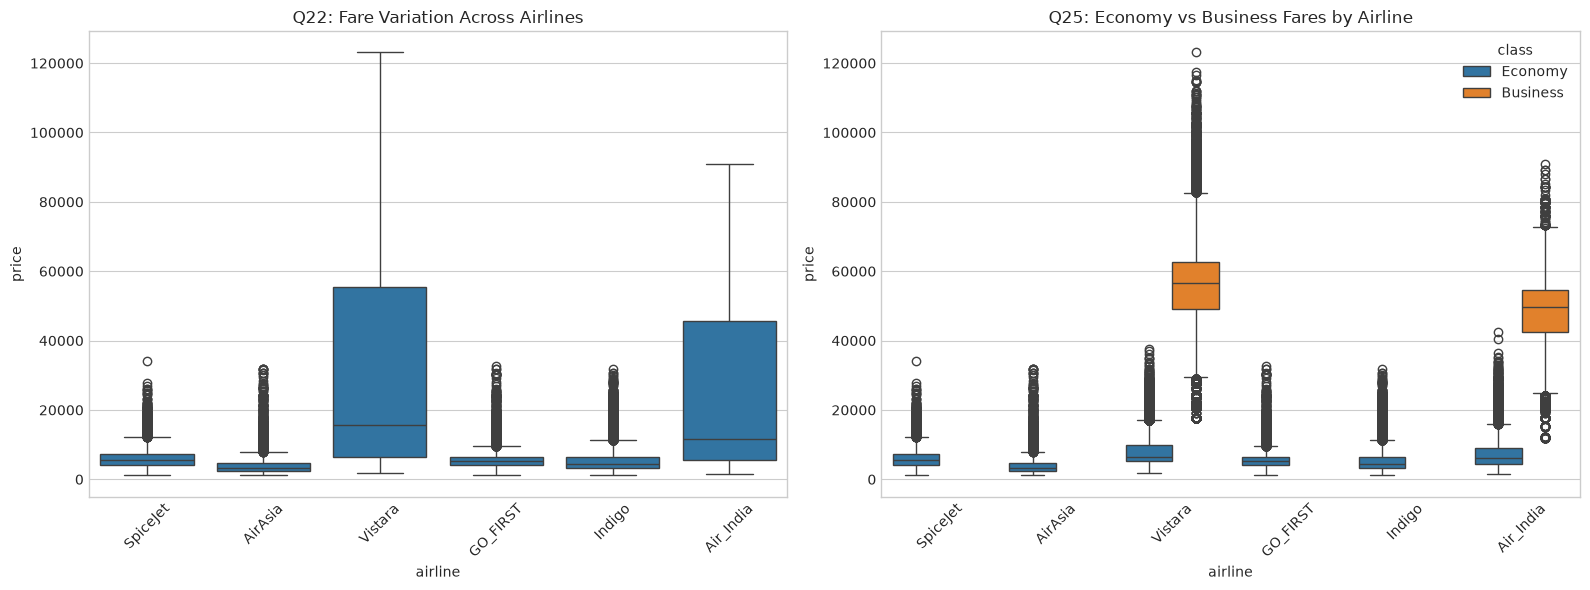


Q27 - % Records below overall median (₹7425.0):
 airline
AirAsia      91.172816
GO_FIRST     87.696889
Indigo       81.145640
SpiceJet     75.785151
Air_India    39.701083
Vistara      31.738869
Name: price, dtype: float64

Q28 - Median Fare by Airline & Stops:
 stops          one  two_or_more    zero
airline                                
AirAsia     3090.0       3175.0  3862.0
Air_India  11561.0      11545.0  8778.0
GO_FIRST    5699.0       5954.0  2410.0
Indigo      4748.0       6858.0  3551.0
SpiceJet    5954.0          NaN  4499.0
Vistara    18566.0       9111.5  9243.0


In [5]:
#sectionC
# Q21, Q23, Q24: Airline stats & rankings
airline_summary = df.groupby('airline')['price'].agg(['count', 'mean', 'median', 'min', 'max', 'std']).sort_values(by='median', ascending=False)
print("Q21, Q23, Q24 - Airline Summary (Sorted by Median Price):\n", airline_summary)

# Q22 & Q25: Boxplots by Airline & Class
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.boxplot(data=df, x='airline', y='price', ax=axes[0])
axes[0].set_title('Q22: Fare Variation Across Airlines')
axes[0].tick_params(axis='x', rotation=45)

sns.boxplot(data=df, x='airline', y='price', hue='class', ax=axes[1])
axes[1].set_title('Q25: Economy vs Business Fares by Airline')
axes[1].tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

# Q27: % of each airline's records below overall median fare
overall_median = df['price'].median()
below_med = df.groupby('airline')['price'].apply(lambda x: (x < overall_median).mean() * 100).sort_values(ascending=False)
print(f"\nQ27 - % Records below overall median (₹{overall_median}):\n", below_med)

# Q28: Airline fare by stops
print("\nQ28 - Median Fare by Airline & Stops:\n", df.pivot_table(index='airline', columns='stops', values='price', aggfunc='median'))

Q29 - Unique Routes: 30
Route_City
Delhi - Mumbai           15289
Mumbai - Delhi           14809
Delhi - Bangalore        14012
Bangalore - Delhi        13756
Bangalore - Mumbai       12939
Mumbai - Bangalore       12885
Mumbai - Kolkata         12602
Delhi - Kolkata          11934
Kolkata - Mumbai         11467
Delhi - Chennai          10780
Kolkata - Delhi          10506
Mumbai - Hyderabad       10470
Mumbai - Chennai         10130
Hyderabad - Mumbai       10064
Bangalore - Kolkata      10028
Kolkata - Bangalore       9824
Chennai - Delhi           9783
Chennai - Mumbai          9338
Delhi - Hyderabad         9328
Bangalore - Hyderabad     8928
Hyderabad - Delhi         8506
Hyderabad - Kolkata       7987
Kolkata - Hyderabad       7897
Hyderabad - Bangalore     7854
Chennai - Kolkata         6983
Kolkata - Chennai         6653
Chennai - Bangalore       6493
Bangalore - Chennai       6410
Hyderabad - Chennai       6395
Chennai - Hyderabad       6103
Name: count, dtype: int64

Q32 - To

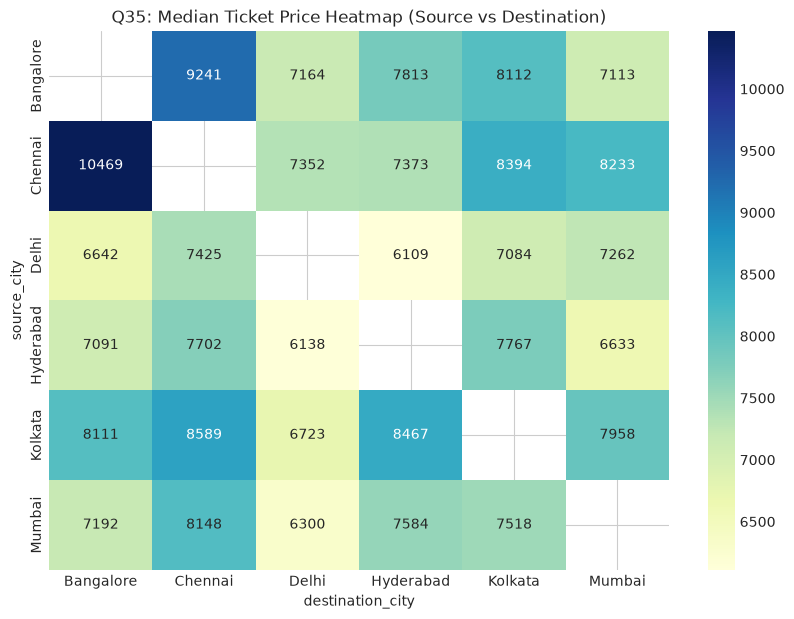


Q36 - Correlation between Route Observation Count and Median Price: -0.5227442120621996

Q37 - Cheapest Airline per Route (Sample 10 routes):
                Route_City   airline   price
0     Bangalore - Chennai   AirAsia  1715.0
6       Bangalore - Delhi   AirAsia  3467.0
12  Bangalore - Hyderabad   AirAsia  1714.0
18    Bangalore - Kolkata   AirAsia  3393.0
24     Bangalore - Mumbai   AirAsia  2203.0
30    Chennai - Bangalore   AirAsia  1548.0
36        Chennai - Delhi   AirAsia  2477.0
44    Chennai - Hyderabad  GO_FIRST  1105.0
48      Chennai - Kolkata   AirAsia  2361.0
54       Chennai - Mumbai   AirAsia  1830.0


In [6]:
#section D
# Q29 & Q30: Route feature engineering
df['Route_City'] = df['source_city'] + ' - ' + df['destination_city']
print(f"Q29 - Unique Routes: {df['Route_City'].nunique()}")
print(df['Route_City'].value_counts())

# Q32 & Q33: Route average/median & directional comparison
route_stats = df.groupby('Route_City')['price'].agg(['count', 'mean', 'median']).sort_values(by='median', ascending=False)
print("\nQ32 - Top 5 Most Expensive Routes:\n", route_stats.head(5))
print("\nQ32 - Bottom 5 Cheapest Routes:\n", route_stats.tail(5))
print("\nQ33 - Delhi-Mumbai vs Mumbai-Delhi:\n", route_stats.loc[['Delhi - Mumbai', 'Mumbai - Delhi']])

# Q34 & Q35: Pivot table & Heatmap
pivot_route = df.pivot_table(index='source_city', columns='destination_city', values='price', aggfunc='median')
plt.figure(figsize=(10, 7))
sns.heatmap(pivot_route, annot=True, fmt='.0f', cmap='YlGnBu')
plt.title('Q35: Median Ticket Price Heatmap (Source vs Destination)')
plt.show()

# Q36 & Q37: Flight count vs median fare & cheapest airline per route
print("\nQ36 - Correlation between Route Observation Count and Median Price:", route_stats['count'].corr(route_stats['median']))
cheapest_per_route = df.groupby(['Route_City', 'airline'])['price'].median().reset_index()
cheapest_idx = cheapest_per_route.groupby('Route_City')['price'].idxmin()
print("\nQ37 - Cheapest Airline per Route (Sample 10 routes):\n", cheapest_per_route.loc[cheapest_idx].head(10))

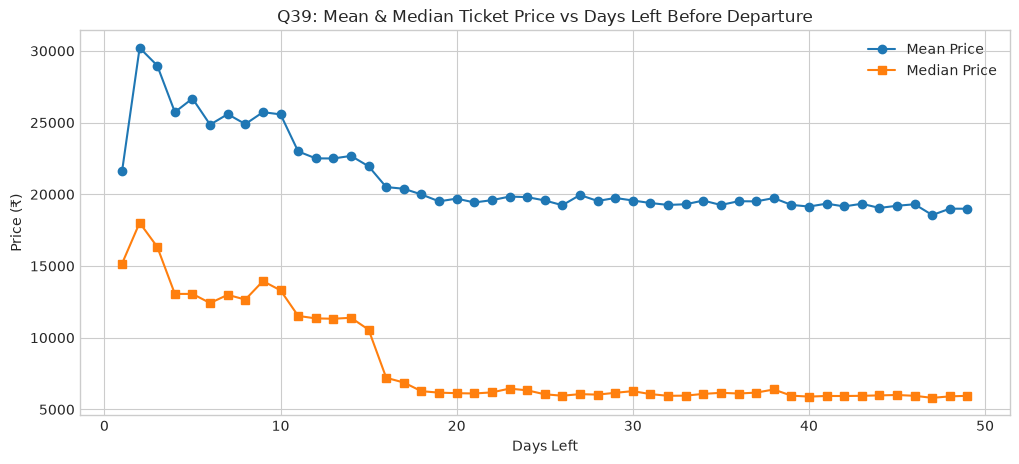

Q40 & Q41 - Booking Window Price Summary:
                 count          mean   median
booking_window                              
0-3 days        10201  28068.681894  16572.0
4-7 days        21912  25698.242059  12978.0
8-15 days       49145  23534.110876  11893.0
16-30 days      97234  19754.193214   6228.5
31-45 days      97200  19335.684475   6056.0
46-60 days      24461  18963.825600   5896.0


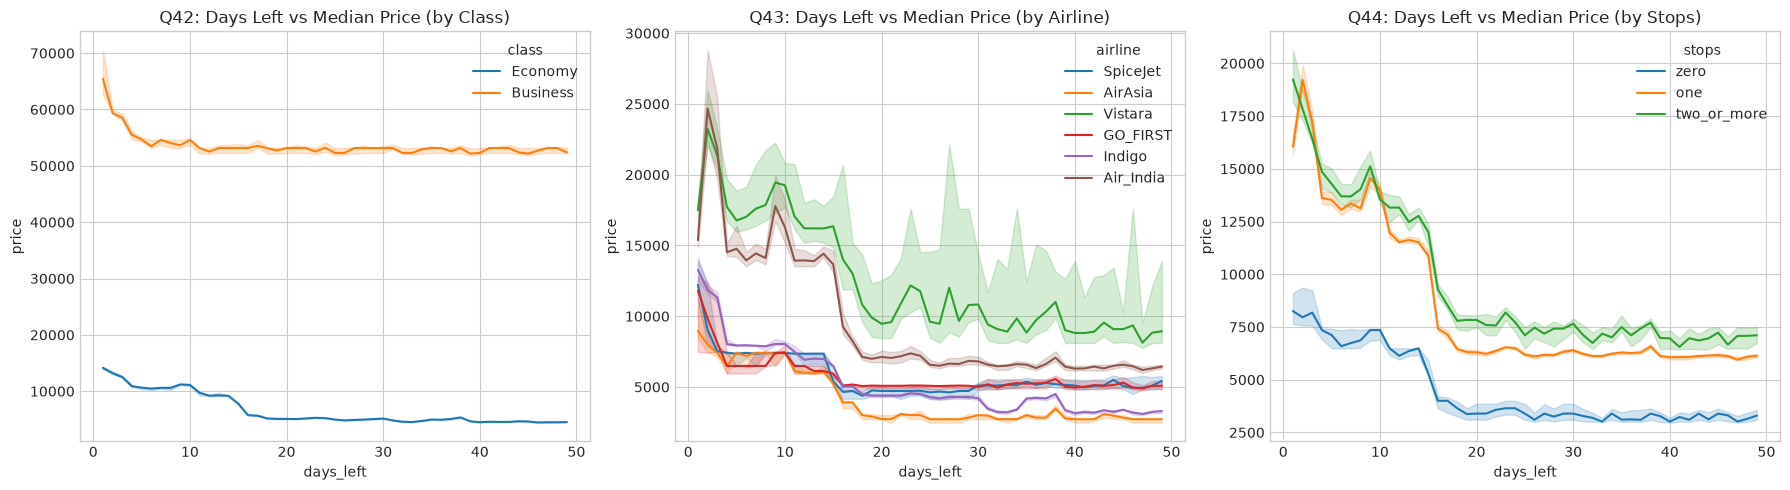


Q46 - Median Price Surge from 46-60 days (₹5896.0) to 0-3 days (₹16572.0): +181.07%


In [7]:
#secion E
# Q38 & Q39: Days Left trend
days_trend = df.groupby('days_left')['price'].agg(['mean', 'median']).reset_index()
plt.figure(figsize=(12, 5))
plt.plot(days_trend['days_left'], days_trend['mean'], label='Mean Price', marker='o')
plt.plot(days_trend['days_left'], days_trend['median'], label='Median Price', marker='s')
plt.title('Q39: Mean & Median Ticket Price vs Days Left Before Departure')
plt.xlabel('Days Left')
plt.ylabel('Price (₹)')
plt.legend()
plt.show()

# Q40 & Q41: Booking window bins
bins = [0, 3, 7, 15, 30, 45, 60, 100]
labels = ['0-3 days', '4-7 days', '8-15 days', '16-30 days', '31-45 days', '46-60 days', '60+ days']
df['booking_window'] = pd.cut(df['days_left'], bins=bins, labels=labels)

window_summary = df.groupby('booking_window', observed=True)['price'].agg(['count', 'mean', 'median'])
print("Q40 & Q41 - Booking Window Price Summary:\n", window_summary)

# Q42, Q43, Q44: Booking window by Class, Airline, and Stops
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.lineplot(data=df, x='days_left', y='price', hue='class', estimator='median', ax=axes[0])
axes[0].set_title('Q42: Days Left vs Median Price (by Class)')

sns.lineplot(data=df, x='days_left', y='price', hue='airline', estimator='median', ax=axes[1])
axes[1].set_title('Q43: Days Left vs Median Price (by Airline)')

sns.lineplot(data=df, x='days_left', y='price', hue='stops', estimator='median', ax=axes[2])
axes[2].set_title('Q44: Days Left vs Median Price (by Stops)')
plt.tight_layout()
plt.show()

# Q46: % change between earliest (46-60 days) and latest (0-3 days)
earliest_med = window_summary.loc['46-60 days', 'median']
latest_med = window_summary.loc['0-3 days', 'median']
pct_surge = ((latest_med - earliest_med) / earliest_med) * 100
print(f"\nQ46 - Median Price Surge from 46-60 days (₹{earliest_med}) to 0-3 days (₹{latest_med}): +{pct_surge:.2f}%")

In [8]:
#section F
# Q47: Duration vs Price correlations
pearson_r, _ = stats.pearsonr(df['duration'], df['price'])
spearman_r, _ = stats.spearmanr(df['duration'], df['price'])
print(f"Q47 - Duration vs Price | Pearson r: {pearson_r:.4f} | Spearman rho: {spearman_r:.4f}")

# Q48, Q50, Q51: Median prices by Stops, Departure Time, Arrival Time
print("\nQ48 - Median Price by Stops:\n", df.groupby('stops')['price'].median())
print("\nQ50 - Median Price by Departure Time:\n", df.groupby('departure_time')['price'].median().sort_values(ascending=False))
print("\nQ51 - Median Price by Arrival Time:\n", df.groupby('arrival_time')['price'].median().sort_values(ascending=False))

# Q52 & Q54: Duration by stops & Duration-Price correlation by Class
print("\nQ52 - Duration Stats by Stops:\n", df.groupby('stops')['duration'].agg(['mean', 'median', 'min', 'max']))
for cls in ['Economy', 'Business']:
    sub = df[df['class'] == cls]
    print(f"Q54 - {cls} Duration-Price Pearson r: {sub['duration'].corr(sub['price']):.4f}")

# BONUS: Predictive Regression Model (Completes "and Prediction" in project title)
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error

ml_df = df.drop(columns=['flight', 'Route_City', 'booking_window'])
ml_df = pd.get_dummies(ml_df, drop_first=True)

X = ml_df.drop(columns=['price'])
y = ml_df['price']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

rf = RandomForestRegressor(n_estimators=50, max_depth=15, n_jobs=-1, random_state=42)
rf.fit(X_train, y_train)
preds = rf.predict(X_test)

print("\n--- Predictive Model Results (Random Forest) ---")
print(f"R² Score: {r2_score(y_test, preds):.4f}")
print(f"MAE: ₹{mean_absolute_error(y_test, preds):.2f}")
print(f"RMSE: ₹{root_mean_squared_error(y_test, preds):.2f}")

Q47 - Duration vs Price | Pearson r: 0.2042 | Spearman rho: 0.3188

Q48 - Median Price by Stops:
 stops
one            7959.0
two_or_more    8307.0
zero           4499.0
Name: price, dtype: float64

Q50 - Median Price by Departure Time:
 departure_time
Morning          8112.0
Night            7813.0
Evening          7425.0
Early_Morning    7212.0
Afternoon        6663.0
Late_Night       4499.0
Name: price, dtype: float64

Q51 - Median Price by Arrival Time:
 arrival_time
Evening          8854.0
Morning          7687.0
Night            7584.0
Afternoon        6714.0
Early_Morning    5800.0
Late_Night       4867.0
Name: price, dtype: float64

Q52 - Duration Stats by Stops:
                   mean  median   min    max
stops                                      
one          13.496514   12.25  2.92  49.83
two_or_more  15.317141   12.67  3.92  49.83
zero          2.191324    2.25  0.83   3.58
Q54 - Economy Duration-Price Pearson r: 0.2884
Q54 - Business Duration-Price Pearson r: 0.2427

---